In [2]:
import os

test_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

print("📁 Folders inside test_dir:")
print(sorted(os.listdir(test_dir)))

📁 Folders inside test_dir:
['glioma', 'meningioma', 'notumor', 'pituitary']


In [6]:
!pip install timm

  Using cached timm-1.0.27-py3-none-any.whl.metadata (40 kB)
  Using cached pyyaml-6.0.3-cp311-cp311-win_amd64.whl.metadata (2.4 kB)
  Using cached huggingface_hub-1.20.1-py3-none-any.whl.metadata (14 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached click-8.4.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.5.1-cp37-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached typer-0.25.1-py3-none-any.whl.metadata (15 kB)
  Using cached anyio-4.14.0-py3-none-any.whl.metadata (4.6 kB)
  Using cached certifi-2026.6.17-py3-none-any.whl.metadata (2.5 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached idna-3.18-py3-none-any.whl.metadata (6.1 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cache

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, models
from PIL import Image
import os
import numpy as np
from sklearn.metrics import classification_report
from timm import create_model
from tqdm import tqdm

# --------------------------
# ✅ Device Setup
# --------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {device}")

# --------------------------
# ✅ Define Model Architectures
# --------------------------

# DenseNet121
densenet = models.densenet121(pretrained=False)

# Match saved checkpoint structure
densenet.classifier = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(1024, 4)
)

# InceptionV4
inception = create_model(
    "inception_v4",
    pretrained=False,
    num_classes=4
)

# --------------------------
# ✅ Load Weights
# --------------------------

densenet_path = r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\densenet121\densenet121_best_model.pth"

inception_path = r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model.pth"

densenet.load_state_dict(
    torch.load(
        densenet_path,
        map_location=device
    )
)

inception.load_state_dict(
    torch.load(
        inception_path,
        map_location=device
    )
)

densenet.to(device).eval()
inception.to(device).eval()

print("✅ DenseNet121 loaded")
print("✅ InceptionV4 loaded")

# --------------------------
# ✅ Transform
# --------------------------
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# --------------------------
# ✅ Dataset Paths
# --------------------------
test_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

# IMPORTANT: Match folder order
classes = [
    'glioma',
    'meningioma',
    'notumor',
    'pituitary'
]

image_paths = []
true_labels = []

for class_idx, class_name in enumerate(classes):

    class_path = os.path.join(
        test_dir,
        class_name
    )

    for fname in os.listdir(class_path):

        if fname.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        ):

            image_paths.append(
                os.path.join(class_path, fname)
            )

            true_labels.append(
                class_idx
            )

print(f"🔎 Found {len(image_paths)} test images")

# --------------------------
# 🔮 Ensemble Inference
# --------------------------
all_preds = []

for path in tqdm(
    image_paths,
    desc="🔮 Predicting"
):

    try:

        img = Image.open(
            path
        ).convert("RGB")

        img_tensor = transform(
            img
        ).unsqueeze(0).to(device)

        with torch.no_grad():

            out1 = densenet(
                img_tensor
            )

            out2 = inception(
                img_tensor
            )

            prob1 = F.softmax(
                out1,
                dim=1
            )

            prob2 = F.softmax(
                out2,
                dim=1
            )

            # Weighted Ensemble
            avg_prob = (
                0.1 * prob1 +
                0.9 * prob2
            )

            pred = avg_prob.argmax(
                dim=1
            ).item()

        all_preds.append(
            pred
        )

    except Exception as e:

        print(
            f"❌ Failed on {path}: {e}"
        )

        all_preds.append(-1)

# --------------------------
# 📊 Evaluation
# --------------------------
valid_preds = [
    p for p in all_preds
    if p != -1
]

valid_labels = [
    t
    for p, t in zip(
        all_preds,
        true_labels
    )
    if p != -1
]

print("\n📋 Ensemble Classification Report:\n")

print(
    classification_report(
        valid_labels,
        valid_preds,
        target_names=classes
    )
)

✅ Using device: cuda


C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_9992\892085359.py:47: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(
C:\Users\Rashmitha R Nayak\AppData\Lo

✅ DenseNet121 loaded
✅ InceptionV4 loaded
🔎 Found 1311 test images


🔮 Predicting: 100%|██████████| 1311/1311 [01:32<00:00, 14.23it/s]


📋 Ensemble Classification Report:

              precision    recall  f1-score   support

      glioma       0.84      0.36      0.50       300
  meningioma       0.37      0.99      0.53       306
     notumor       0.88      0.76      0.81       405
   pituitary       0.92      0.04      0.08       300

    accuracy                           0.55      1311
   macro avg       0.75      0.53      0.48      1311
weighted avg       0.76      0.55      0.51      1311



In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, models
from PIL import Image
import os
from sklearn.metrics import classification_report
from timm import create_model
from tqdm import tqdm
import warnings

warnings.filterwarnings("ignore")

# --------------------------
# ✅ Device Setup
# --------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {device}")

# --------------------------
# ✅ Load DenseNet121 Model
# --------------------------
densenet = models.densenet121(pretrained=False)

densenet.classifier = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(1024, 4)
)

densenet.load_state_dict(
    torch.load(
        r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\densenet121\densenet121_best_model.pth",
        map_location=device
    )
)

densenet.eval().to(device)

# --------------------------
# ✅ Load InceptionV4 Model
# --------------------------
inception = create_model(
    "inception_v4",
    pretrained=False,
    num_classes=4
)

inception.load_state_dict(
    torch.load(
        r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model.pth",
        map_location=device
    )
)

inception.eval().to(device)

print("✅ DenseNet121 loaded")
print("✅ InceptionV4 loaded")

# --------------------------
# ✅ Transform
# --------------------------
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# --------------------------
# ✅ Dataset Paths
# --------------------------
test_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

# Match actual folder order
classes = [
    'glioma',
    'meningioma',
    'notumor',
    'pituitary'
]

image_paths = []
true_labels = []

for class_idx, class_name in enumerate(classes):

    class_path = os.path.join(
        test_dir,
        class_name
    )

    for fname in os.listdir(class_path):

        if fname.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        ):

            image_paths.append(
                os.path.join(class_path, fname)
            )

            true_labels.append(
                class_idx
            )

print(f"🔎 Found {len(image_paths)} test images.")

# --------------------------
# 🔮 Ensemble Inference
# --------------------------
all_preds = []

for path in tqdm(
    image_paths,
    desc="🔮 Predicting"
):

    try:

        img = Image.open(path).convert("RGB")

        img_tensor = transform(
            img
        ).unsqueeze(0).to(device)

        with torch.no_grad():

            out_densenet = densenet(
                img_tensor
            )

            out_inception = inception(
                img_tensor
            )

            prob_densenet = F.softmax(
                out_densenet,
                dim=1
            )

            prob_inception = F.softmax(
                out_inception,
                dim=1
            )

            # Current Ensemble Weights
            avg_prob = (
                0.6 * prob_densenet +
                0.4 * prob_inception
            )

            pred = avg_prob.argmax(
                dim=1
            ).item()

        all_preds.append(pred)

    except Exception as e:

        print(
            f"❌ Failed on {path}: {e}"
        )

        all_preds.append(-1)

# --------------------------
# 📊 Evaluation
# --------------------------
valid_preds = [
    p for p in all_preds
    if p != -1
]

valid_labels = [
    t
    for p, t in zip(
        all_preds,
        true_labels
    )
    if p != -1
]

print("\n📋 Ensemble Classification Report:\n")

print(
    classification_report(
        valid_labels,
        valid_preds,
        target_names=classes
    )
)

✅ Using device: cuda
🔎 Found 1095 test images.


🔮 Predicting: 100%|███████████████████████████████████████████████████████████████| 1095/1095 [01:02<00:00, 17.62it/s]



📋 Ensemble Classification Report:
              precision    recall  f1-score   support

      glioma       1.00      0.99      0.99       300
  meningioma       0.98      0.97      0.97       200
   pituitary       0.00      0.00      0.00       295
     notumor       0.00      0.00      0.00       300

    accuracy                           0.45      1095
   macro avg       0.49      0.49      0.49      1095
weighted avg       0.45      0.45      0.45      1095



In [11]:
import os

print(os.path.exists(r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\densenet121\densenet121_best_model.pth"))
print(os.path.exists(r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model.pth"))

True
True


In [12]:
print("Loading DenseNet...")
densenet.load_state_dict(
    torch.load(
        densenet_path,
        map_location=device
    )
)

print("Loading Inception...")
inception.load_state_dict(
    torch.load(
        inception_path,
        map_location=device
    )
)

Loading DenseNet...


C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_9992\1721291896.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


Loading Inception...


C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_9992\1721291896.py:11: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


<All keys matched successfully>

In [15]:
import os

print(os.path.exists(
    r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\densenet121\densenet121_best_model_weights.pth"
))

print(os.path.exists(
    r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model_weights.pth"
))

True
True


In [16]:
import torch
import torch.nn.functional as F
from torchvision import transforms, models
from PIL import Image
import os
from sklearn.metrics import classification_report
from timm import create_model
from tqdm import tqdm
import torch.nn as nn

# --------------------------
# ✅ Device Setup
# --------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {device}")

# --------------------------
# ✅ Dataset + Class Info
# --------------------------
test_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

classes = sorted([
    d for d in os.listdir(test_dir)
    if os.path.isdir(os.path.join(test_dir, d))
])

print("✅ Aligned classes:", classes)

# --------------------------
# ✅ DenseNet121
# --------------------------
densenet = models.densenet121(pretrained=False)

densenet.classifier = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(1024, len(classes))
)

densenet.load_state_dict(
    torch.load(
        r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\densenet121\densenet121_best_model_weights.pth",
        map_location=device
    )
)

densenet.to(device).eval()

# --------------------------
# ✅ InceptionV4
# --------------------------
inception = create_model(
    "inception_v4",
    pretrained=False,
    num_classes=len(classes)
)

inception.load_state_dict(
    torch.load(
        r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model_weights.pth",
        map_location=device
    )
)

inception.to(device).eval()


# --------------------------
# ✅ Transform
# --------------------------
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# --------------------------
# ✅ Collect Test Images
# --------------------------
image_paths = []
true_labels = []

for class_idx, class_name in enumerate(classes):

    class_path = os.path.join(
        test_dir,
        class_name
    )

    for fname in os.listdir(class_path):

        if fname.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        ):

            image_paths.append(
                os.path.join(class_path, fname)
            )

            true_labels.append(
                class_idx
            )

print(f"🔎 Found {len(image_paths)} test images")

# --------------------------
# 🔮 Ensemble Inference
# --------------------------
all_preds = []

temperature = 2.0

for path in tqdm(
    image_paths,
    desc="🔮 Predicting"
):

    try:

        img = Image.open(
            path
        ).convert("RGB")

        img_tensor = transform(
            img
        ).unsqueeze(0).to(device)

        with torch.no_grad():

            out1 = densenet(img_tensor) / temperature
            out2 = inception(img_tensor) / temperature

            prob1 = F.softmax(
                out1,
                dim=1
            )

            prob2 = F.softmax(
                out2,
                dim=1
            )

            # Ensemble weights
            avg_prob = (
                0.6 * prob1 +
                0.4 * prob2
            )

            pred = avg_prob.argmax(
                dim=1
            ).item()

        all_preds.append(pred)

    except Exception as e:

        print(f"❌ Failed on {path}: {e}")

        all_preds.append(-1)

# --------------------------
# 📊 Evaluation
# --------------------------
valid_preds = [
    p for p in all_preds
    if p != -1
]

valid_labels = [
    t
    for p, t in zip(
        all_preds,
        true_labels
    )
    if p != -1
]

print("\n📋 Ensemble Classification Report:\n")

print(
    classification_report(
        valid_labels,
        valid_preds,
        target_names=classes
    )
)

✅ Using device: cuda
✅ Aligned classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_9992\299606072.py:40: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(
C:\Users\Rashmitha R Nayak\AppData\Lo

🔎 Found 1311 test images


🔮 Predicting: 100%|██████████| 1311/1311 [01:26<00:00, 15.20it/s]


📋 Ensemble Classification Report:

              precision    recall  f1-score   support

      glioma       1.00      0.99      0.99       300
  meningioma       0.99      0.97      0.98       306
     notumor       0.99      1.00      1.00       405
   pituitary       0.98      1.00      0.99       300

    accuracy                           0.99      1311
   macro avg       0.99      0.99      0.99      1311
weighted avg       0.99      0.99      0.99      1311



In [35]:
# Save DenseNet121 weights
torch.save(densenet.state_dict(), "densenet121_best_model_weights.pth")

# Save InceptionV4 weights
torch.save(inception.state_dict(), "inceptionv4_best_model_weights.pth")


In [36]:
import json

ensemble_config = {
    "model_1": {
        "arch": "densenet121",
        "weights": "densenet121_best_model_weights.pth",
        "weight": 0.6
    },
    "model_2": {
        "arch": "inception_v4",
        "weights": "inceptionv4_best_model_weights.pth",
        "weight": 0.4
    },
    "temperature": 2.0,
    "class_weights": [1.0, 1.0, 0.5, 1.0],  # example
    "classes": ['glioma', 'meningioma', 'notumor', 'pituitary']
}

with open("ensemble_config.json", "w") as f:
    json.dump(ensemble_config, f, indent=4)


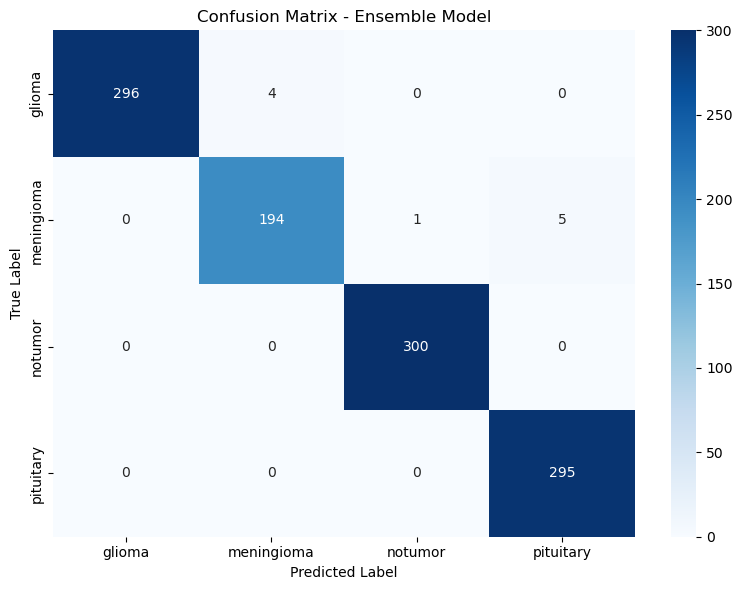

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# --------------------------
# 🧩 Confusion Matrix
# --------------------------
cm = confusion_matrix(valid_labels, valid_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Ensemble Model")
plt.tight_layout()
plt.show()


In [38]:
import pandas as pd

# Save image paths, true labels and predictions
results_df = pd.DataFrame({
    "image_path": image_paths,
    "true_label": [classes[t] for t in true_labels],
    "predicted_label": [classes[p] if p != -1 else "invalid" for p in all_preds]
})

results_df.to_csv("ensemble_results.csv", index=False)
print("✅ Saved: ensemble_results.csv")


✅ Saved: ensemble_results.csv


In [40]:
# Ensure you've already run inference and have:
# - image_paths: list of image file paths
# - valid_preds: predicted class indices
# - valid_labels: ground-truth class indices
# - classes: list of class names (sorted and aligned)

print("\n📋 Prediction Summary from Test Set\n" + "="*40)

for idx, (img_path, true_idx, pred_idx) in enumerate(zip(image_paths, true_labels, all_preds)):
    if pred_idx == -1:
        continue  # skip failed predictions

    actual = classes[true_idx]
    predicted = classes[pred_idx]
    status = "✅" if actual == predicted else "❌"
    filename = os.path.basename(img_path)

    print(f"🖼️  Image   : {filename}")
    print(f"📌 Actual   : {actual}")
    print(f"🎯 Predicted: {predicted} {status}")
    print("-" * 40)



📋 Prediction Summary from Test Set
🖼️  Image   : Te-glTr_0000.jpg
📌 Actual   : glioma
🎯 Predicted: glioma ✅
----------------------------------------
🖼️  Image   : Te-glTr_0001.jpg
📌 Actual   : glioma
🎯 Predicted: glioma ✅
----------------------------------------
🖼️  Image   : Te-glTr_0002.jpg
📌 Actual   : glioma
🎯 Predicted: glioma ✅
----------------------------------------
🖼️  Image   : Te-glTr_0003.jpg
📌 Actual   : glioma
🎯 Predicted: glioma ✅
----------------------------------------
🖼️  Image   : Te-glTr_0004.jpg
📌 Actual   : glioma
🎯 Predicted: glioma ✅
----------------------------------------
🖼️  Image   : Te-glTr_0005.jpg
📌 Actual   : glioma
🎯 Predicted: glioma ✅
----------------------------------------
🖼️  Image   : Te-glTr_0006.jpg
📌 Actual   : glioma
🎯 Predicted: glioma ✅
----------------------------------------
🖼️  Image   : Te-glTr_0007.jpg
📌 Actual   : glioma
🎯 Predicted: glioma ✅
----------------------------------------
🖼️  Image   : Te-glTr_0008.jpg
📌 Actual   : glioma
🎯

ROC Evaluation: 100%|██████████| 1311/1311 [01:19<00:00, 16.55it/s]


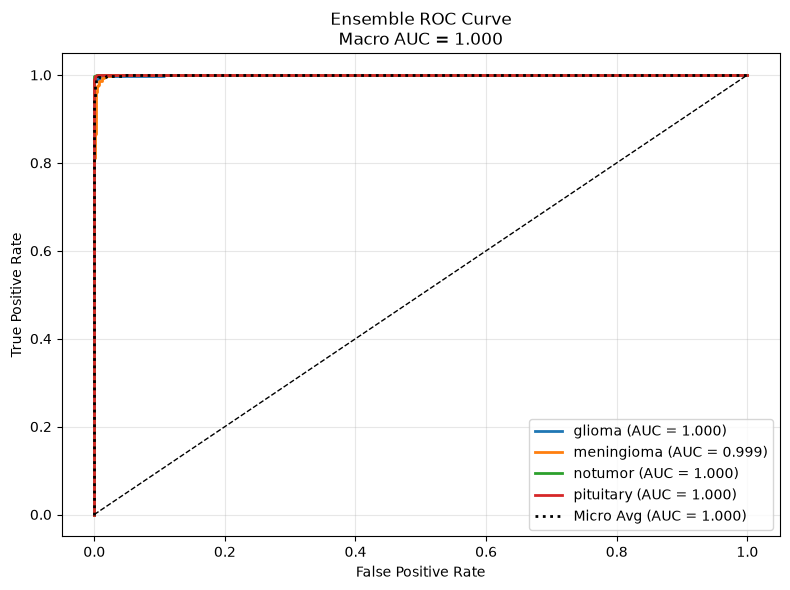


Per-Class AUC
glioma: 0.9996
meningioma: 0.9993
notumor: 1.0000
pituitary: 1.0000

Macro AUC : 0.9997
Micro AUC : 0.9996


In [18]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_curve,
    auc,
    roc_auc_score
)

# ------------------------------------
# ROC-AUC Evaluation
# ------------------------------------

all_probs = []

temperature = 2.0

for path in tqdm(
    image_paths,
    desc="ROC Evaluation"
):

    img = Image.open(path).convert("RGB")

    img_tensor = transform(
        img
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        out1 = densenet(img_tensor) / temperature
        out2 = inception(img_tensor) / temperature

        prob1 = F.softmax(
            out1,
            dim=1
        )

        prob2 = F.softmax(
            out2,
            dim=1
        )

        # SAME ensemble weights used above
        avg_prob = (
            0.6 * prob1 +
            0.4 * prob2
        )

    all_probs.append(
        avg_prob.squeeze().cpu().numpy()
    )

# ------------------------------------
# Convert to numpy
# ------------------------------------

all_probs = np.array(all_probs)
all_labels = np.array(true_labels)

num_classes = len(classes)

y_true = label_binarize(
    all_labels,
    classes=list(range(num_classes))
)

# ------------------------------------
# ROC Curves
# ------------------------------------

fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):

    fpr[i], tpr[i], _ = roc_curve(
        y_true[:, i],
        all_probs[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

# Macro AUC
macro_auc = roc_auc_score(
    y_true,
    all_probs,
    average="macro",
    multi_class="ovr"
)

# Micro AUC
fpr_micro, tpr_micro, _ = roc_curve(
    y_true.ravel(),
    all_probs.ravel()
)

micro_auc = auc(
    fpr_micro,
    tpr_micro
)

# ------------------------------------
# Plot ROC
# ------------------------------------

plt.figure(figsize=(8, 6))

colors = [
    'tab:blue',
    'tab:orange',
    'tab:green',
    'tab:red'
]

for i, class_name in enumerate(classes):

    plt.plot(
        fpr[i],
        tpr[i],
        lw=2,
        color=colors[i],
        label=f"{class_name} (AUC = {roc_auc[i]:.3f})"
    )

plt.plot(
    fpr_micro,
    tpr_micro,
    color='black',
    linestyle=':',
    lw=2,
    label=f"Micro Avg (AUC = {micro_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    lw=1
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"Ensemble ROC Curve\n"
    f"Macro AUC = {macro_auc:.3f}"
)

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "Ensemble_ROC_AUC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------
# Print Results
# ------------------------------------

print("\nPer-Class AUC")

for i, class_name in enumerate(classes):
    print(
        f"{class_name}: {roc_auc[i]:.4f}"
    )

print(f"\nMacro AUC : {macro_auc:.4f}")
print(f"Micro AUC : {micro_auc:.4f}")